In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn sqlalchemy pymysql openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.2 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving HR_Job_Placement_Dataset.csv to HR_Job_Placement_Dataset.csv


In [ ]:
df = pd.read_csv("HR_Job_Placement_Dataset.csv")

In [ ]:
import os
print(os.listdir())
file_name = os.listdir()[0]

if file_name.endswith(".csv"):
    df = pd.read_csv(file_name)
elif file_name.endswith((".xlsx", ".xls")):
    df = pd.read_excel(file_name)

print(df.shape)

['.config', 'HR_Job_Placement_Dataset.csv', 'sample_data']
(51500, 26)


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Rows: 51500
Columns: 26


,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,...,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,...,5.805850,Tier 3,Not Matched,Medium,Not Required,15.0,No,18.0,Not Willing,Not Placed
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,...,10.807739,Tier 1,Matched,High,Required,0.0,NaN,NaN,Not Willing,Not Placed
2,33,Female,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,...,5.476839,Tier 3,Not Matched,Low,Not Required,0.0,No,3.0,Not Willing,Placed
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,...,9.980580,Tier 2,Matched,Low,Not Required,0.0,Yes,6.0,NaN,Not Placed
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,...,8.921233,Tier 2,Matched,Medium,Not Required,0.0,No,3.0,Willing,Not Placed


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51500 entries, 0 to 51499
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age_years                  51500 non-null  int64  
 1   gender                     51500 non-null  object 
 2   ssc_percentage             48919 non-null  float64
 3   hsc_percentage             49435 non-null  float64
 4   degree_percentage          51500 non-null  float64
 5   degree_specialization      51500 non-null  object 
 6   technical_score            51500 non-null  float64
 7   aptitude_score             51500 non-null  float64
 8   communication_score        51500 non-null  float64
 9   skills_match_percentage    51500 non-null  float64
 10  certifications_count       51500 non-null  int64  
 11  internship_experience      51500 non-null  object 
 12  years_of_experience        51500 non-null  int64  
 13  career_switch_willingness  43034 non-null  obj

In [ ]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age_years,51500.0,NaN,NaN,NaN,27.505456,4.025385,21.0,24.0,27.0,31.0,34.0
gender,51500,4,Female,24379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ssc_percentage,48919.0,NaN,NaN,NaN,70.002505,7.976314,50.0,64.574733,69.97121,75.389057,95.0
hsc_percentage,49435.0,NaN,NaN,NaN,72.060636,7.916654,50.0,66.720058,72.014383,77.389894,95.0
degree_percentage,51500.0,NaN,NaN,NaN,74.010825,6.945579,55.0,69.305041,73.998187,78.707827,95.0
degree_specialization,51500,5,Others,10463,NaN,NaN,NaN,NaN,NaN,NaN,NaN
technical_score,51500.0,NaN,NaN,NaN,68.027499,11.855145,40.0,59.935988,67.986042,76.049235,100.0
aptitude_score,51500.0,NaN,NaN,NaN,64.005715,9.922397,40.0,57.204237,63.972079,70.727134,100.0
communication_score,51500.0,NaN,NaN,NaN,66.106692,9.907488,45.0,59.252271,66.033268,72.840985,100.0
skills_match_percentage,51500.0,NaN,NaN,NaN,73.937491,11.794258,45.0,65.851924,74.001772,82.112773,100.0


In [ ]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing = missing.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(missing)

,Missing_Count,Missing_Percentage
relocation_willingness,8475,16.456311
layoff_history,8467,16.440777
career_switch_willingness,8466,16.438835
relevant_experience,8426,16.361165
job_role_match,6131,11.904854
ssc_percentage,2581,5.011650
hsc_percentage,2065,4.009709
notice_period_days,1582,3.071845
employment_gap_months,1097,2.130097
gender,0,0.000000


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1376


In [ ]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace(r"[^a-zA-Z0-9_]", "", regex=True)
)

print(df.columns.tolist())

['age_years', 'gender', 'ssc_percentage', 'hsc_percentage', 'degree_percentage', 'degree_specialization', 'technical_score', 'aptitude_score', 'communication_score', 'skills_match_percentage', 'certifications_count', 'internship_experience', 'years_of_experience', 'career_switch_willingness', 'relevant_experience', 'previous_ctc_lpa', 'expected_ctc_lpa', 'company_tier', 'job_role_match', 'competition_level', 'bond_requirement', 'notice_period_days', 'layoff_history', 'employment_gap_months', 'relocation_willingness', 'status']


In [ ]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_columns:
    print("\nCOLUMN:", col)
    print(df[col].value_counts(dropna=False).head(20))


COLUMN: gender
gender
Female    24379
Male      24028
male       1549
female     1544
Name: count, dtype: int64

COLUMN: degree_specialization
degree_specialization
Others                    10463
Electronics               10358
Information Technology    10298
Computer Science          10210
Mechanical                10171
Name: count, dtype: int64

COLUMN: internship_experience
internship_experience
No      25607
Yes     23327
 no      1341
yes      1225
Name: count, dtype: int64

COLUMN: career_switch_willingness
career_switch_willingness
Not Willing    28479
Willing        14555
NaN             8466
Name: count, dtype: int64

COLUMN: relevant_experience
relevant_experience
Relevant        26305
Not Relevant    16769
NaN              8426
Name: count, dtype: int64

COLUMN: company_tier
company_tier
Tier 1     19046
Tier 2     18301
Tier 3     12061
Tier 1       832
Tier 2       755
Tier 3       505
Name: count, dtype: int64

COLUMN: job_role_match
job_role_match
Matched        33456

In [ ]:
for col in categorical_columns:
    df[col] = (
        df[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

In [ ]:
if "gender" in df.columns:
    df["gender"] = df["gender"].replace({
        "m": "male",
        "f": "female"
    })

In [ ]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns

categorical_columns = df.select_dtypes(
    include=["object", "string", "category"]
).columns

In [ ]:
for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

In [ ]:
for col in categorical_columns:
    mode_value = df[col].mode()

    if len(mode_value) > 0:
        df[col] = df[col].fillna(mode_value[0])
    else:
        df[col] = df[col].fillna("unknown")

In [ ]:
print(df.isnull().sum().sum())

0


In [ ]:
before = len(df)
df = df.drop_duplicates()
after = len(df)
print("Duplicates removed:", before - after)
print("New shape:", df.shape)

Duplicates removed: 1500
New shape: (50000, 26)


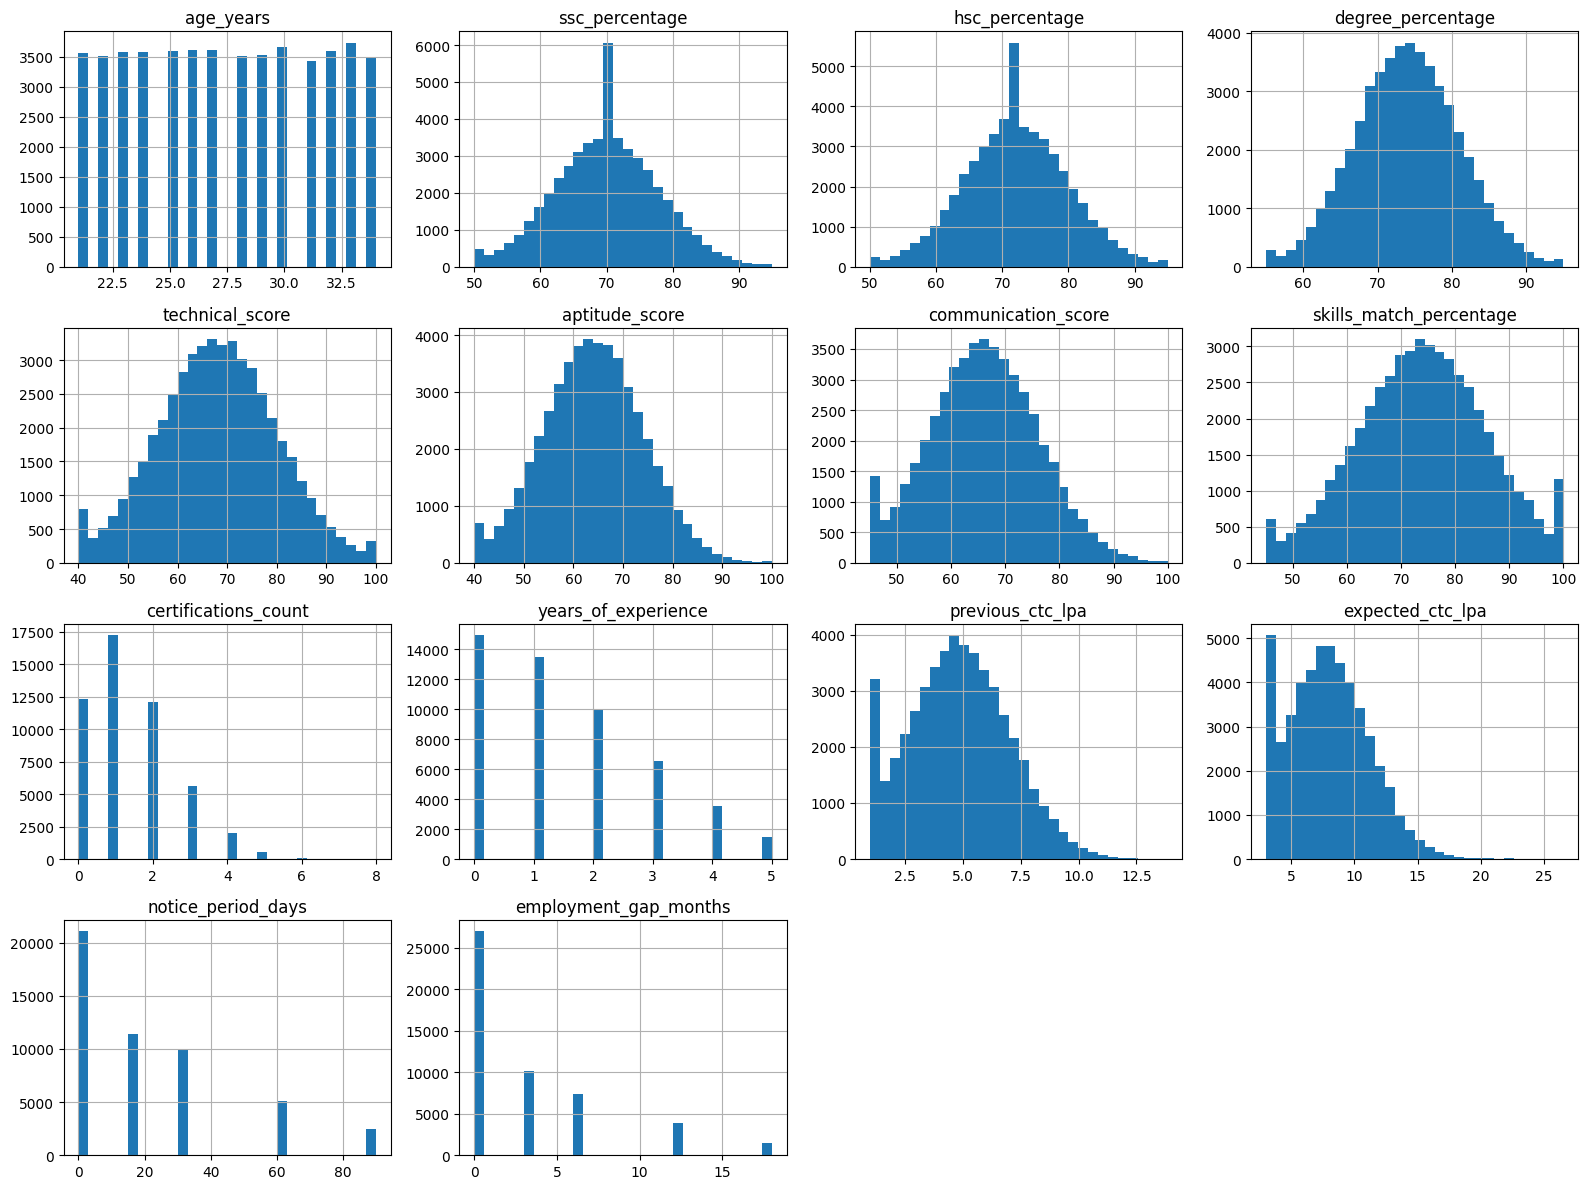

In [ ]:
df.hist(
    figsize=(16, 12),
    bins=30
)

plt.tight_layout()
plt.show()

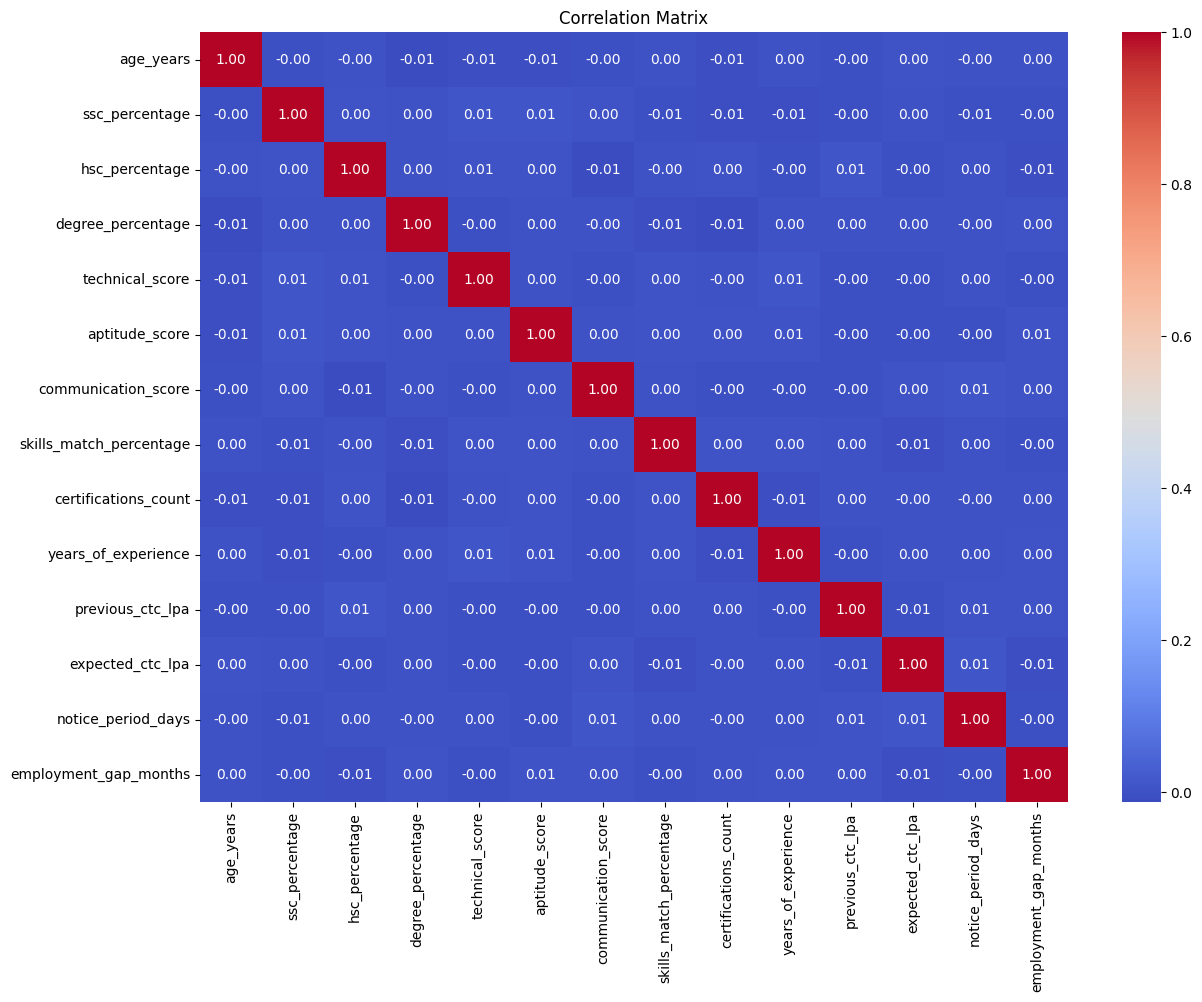

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

In [ ]:
print(df.columns.tolist())

['age_years', 'gender', 'ssc_percentage', 'hsc_percentage', 'degree_percentage', 'degree_specialization', 'technical_score', 'aptitude_score', 'communication_score', 'skills_match_percentage', 'certifications_count', 'internship_experience', 'years_of_experience', 'career_switch_willingness', 'relevant_experience', 'previous_ctc_lpa', 'expected_ctc_lpa', 'company_tier', 'job_role_match', 'competition_level', 'bond_requirement', 'notice_period_days', 'layoff_history', 'employment_gap_months', 'relocation_willingness', 'status']


In [ ]:
target_column = "status"

In [ ]:
print(df[target_column].value_counts())

status
not placed    34870
placed        15130
Name: count, dtype: Int64


In [ ]:
df["target"] = df[target_column].map({
    "placed": 1,
    "not placed": 0
})

In [ ]:
print(df["target"].value_counts())

target
0    34870
1    15130
Name: count, dtype: int64


In [ ]:
if "experience" in df.columns:

    df["experience_category"] = pd.cut(
        df["experience"],
        bins=[-1, 0, 3, 100],
        labels=["Fresher", "Junior", "Senior"]
    )

In [ ]:
if "academic_score" in df.columns:

    df["academic_performance"] = pd.cut(
        df["academic_score"],
        bins=[-np.inf, 50, 70, 85, np.inf],
        labels=[
            "Low",
            "Average",
            "Good",
            "Excellent"
        ]
    )

In [ ]:
if "skills_match_percentage" in df.columns:

    df["skills_match_level"] = pd.cut(
        df["skills_match_percentage"],
        bins=[-1, 50, 75, 100],
        labels=[
            "Low",
            "Medium",
            "High"
        ]
    )

In [ ]:
if "interview_score" in df.columns:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="target",
        y="interview_score"
    )

    plt.xlabel("Job Acceptance")
    plt.ylabel("Interview Score")
    plt.title("Interview Score vs Job Acceptance")

    plt.show()

In [ ]:
acceptance_rate = df["target"].mean() * 100

print(
    f"Job Acceptance Rate: {acceptance_rate:.2f}%"
)

Job Acceptance Rate: 30.26%


In [ ]:
if "company_tier" in df.columns:

    company_analysis = (
        df.groupby("company_tier")["target"]
        .mean()
        .mul(100)
        .reset_index()
    )

    company_analysis.columns = [
        "company_tier",
        "acceptance_rate"
    ]

    display(company_analysis)

,company_tier,acceptance_rate
0,tier 1,29.935250
1,tier 2,30.417140
2,tier 3,30.535539


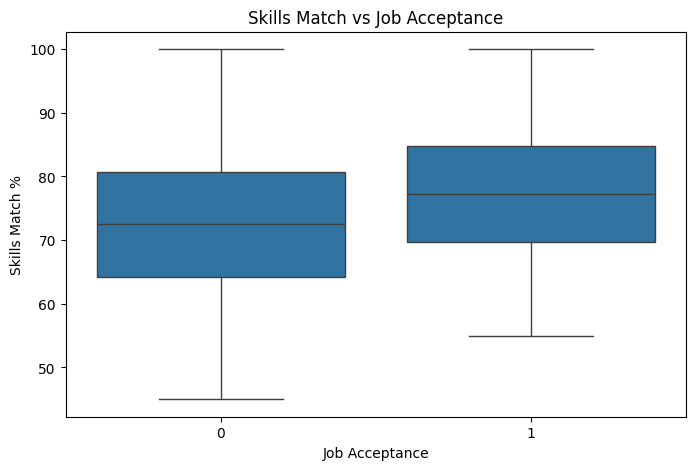

In [ ]:
if "skills_match_percentage" in df.columns:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="target",
        y="skills_match_percentage"
    )

    plt.title("Skills Match vs Job Acceptance")
    plt.xlabel("Job Acceptance")
    plt.ylabel("Skills Match %")

    plt.show()

In [ ]:
X = df.drop(
    columns=[target_column, "target"],
    errors="ignore"
)

y = df["target"]

In [ ]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical:", numeric_features)
print("Categorical:", categorical_features)

Numerical: ['age_years', 'ssc_percentage', 'hsc_percentage', 'degree_percentage', 'technical_score', 'aptitude_score', 'communication_score', 'skills_match_percentage', 'certifications_count', 'years_of_experience', 'previous_ctc_lpa', 'expected_ctc_lpa', 'notice_period_days', 'employment_gap_months']
Categorical: ['gender', 'degree_specialization', 'internship_experience', 'career_switch_willingness', 'relevant_experience', 'company_tier', 'job_role_match', 'competition_level', 'bond_requirement', 'layoff_history', 'relocation_willingness', 'skills_match_level']


In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (40000, 26)
Testing: (10000, 26)


In [ ]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000
    ))
])

logistic_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age_years',
                                                   'ssc_percentage',
                                                   'hsc_percentage',
                                                   'degree_percentage',
                                                   'technical_score',
                                                   'aptitude_score',
                                                   'communication_score',
                                                   'skills_match_percentage',
                                                   'certifications_count',
                                                   'years_of_e...
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender',
                                                   'degree_specialization',
                                                   'internship_experience',
                                                   'career_switch_willingness',
                                                   'relevant_experience',
                                                   'company_tier',
                                                   'job_role_match',
                                                   'competition_level',
                                                   'bond_requirement',
                                                   'layoff_history',
                                                   'relocation_willingness',
                                                   'skills_match_level'])])),
                ('model', LogisticRegression(max_iter=1000))])

In [ ]:
y_pred_lr = logistic_model.predict(X_test)

y_prob_lr = logistic_model.predict_proba(
    X_test
)[:, 1]

In [ ]:
print(
    "Accuracy:",
    accuracy_score(y_test, y_pred_lr)
)

print(
    "Precision:",
    precision_score(y_test, y_pred_lr)
)

print(
    "Recall:",
    recall_score(y_test, y_pred_lr)
)

print(
    "F1 Score:",
    f1_score(y_test, y_pred_lr)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_prob_lr)
)

Accuracy: 0.8664
Precision: 0.7956613016095171
Recall: 0.751487111698612
F1 Score: 0.7729435757987764
ROC-AUC: 0.9383537399132004


In [ ]:
print(
    classification_report(
        y_test,
        y_pred_lr
    )
)

              precision    recall  f1-score   support

           0       0.89      0.92      0.91      6974
           1       0.80      0.75      0.77      3026

    accuracy                           0.87     10000
   macro avg       0.85      0.83      0.84     10000
weighted avg       0.86      0.87      0.87     10000



In [ ]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ))
])

rf_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age_years',
                                                   'ssc_percentage',
                                                   'hsc_percentage',
                                                   'degree_percentage',
                                                   'technical_score',
                                                   'aptitude_score',
                                                   'communication_score',
                                                   'skills_match_percentage',
                                                   'certifications_count',
                                                   'years_of_e...
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender',
                                                   'degree_specialization',
                                                   'internship_experience',
                                                   'career_switch_willingness',
                                                   'relevant_experience',
                                                   'company_tier',
                                                   'job_role_match',
                                                   'competition_level',
                                                   'bond_requirement',
                                                   'layoff_history',
                                                   'relocation_willingness',
                                                   'skills_match_level'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [ ]:
y_pred_rf = rf_model.predict(X_test)

y_prob_rf = rf_model.predict_proba(
    X_test
)[:, 1]

In [ ]:
print(
    "Accuracy:",
    accuracy_score(y_test, y_pred_rf)
)

print(
    "Precision:",
    precision_score(y_test, y_pred_rf)
)

print(
    "Recall:",
    recall_score(y_test, y_pred_rf)
)

print(
    "F1 Score:",
    f1_score(y_test, y_pred_rf)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_prob_rf)
)

Accuracy: 0.8804
Precision: 0.8585423197492164
Recall: 0.7240581625908791
F1 Score: 0.7855862316242381
ROC-AUC: 0.9539170464330643


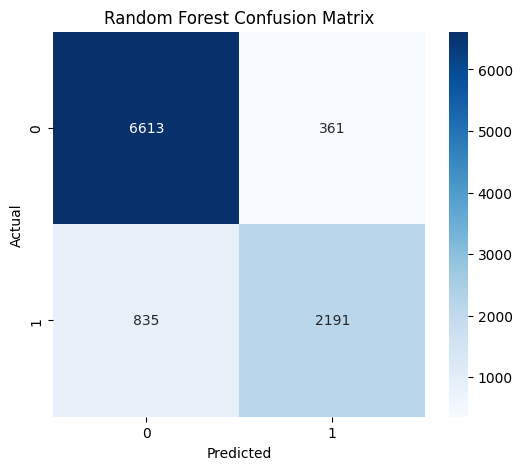

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred_rf
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

In [ ]:
feature_names = (
    rf_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    rf_model
    .named_steps["model"]
    .feature_importances_
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = (
    feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .head(20)
)

display(feature_importance)

,Feature,Importance
4,numeric__technical_score,0.262551
9,numeric__years_of_experience,0.114388
7,numeric__skills_match_percentage,0.072533
11,numeric__expected_ctc_lpa,0.062004
6,numeric__communication_score,0.043076
10,numeric__previous_ctc_lpa,0.042828
5,numeric__aptitude_score,0.032178
3,numeric__degree_percentage,0.030249
1,numeric__ssc_percentage,0.030164
2,numeric__hsc_percentage,0.030061


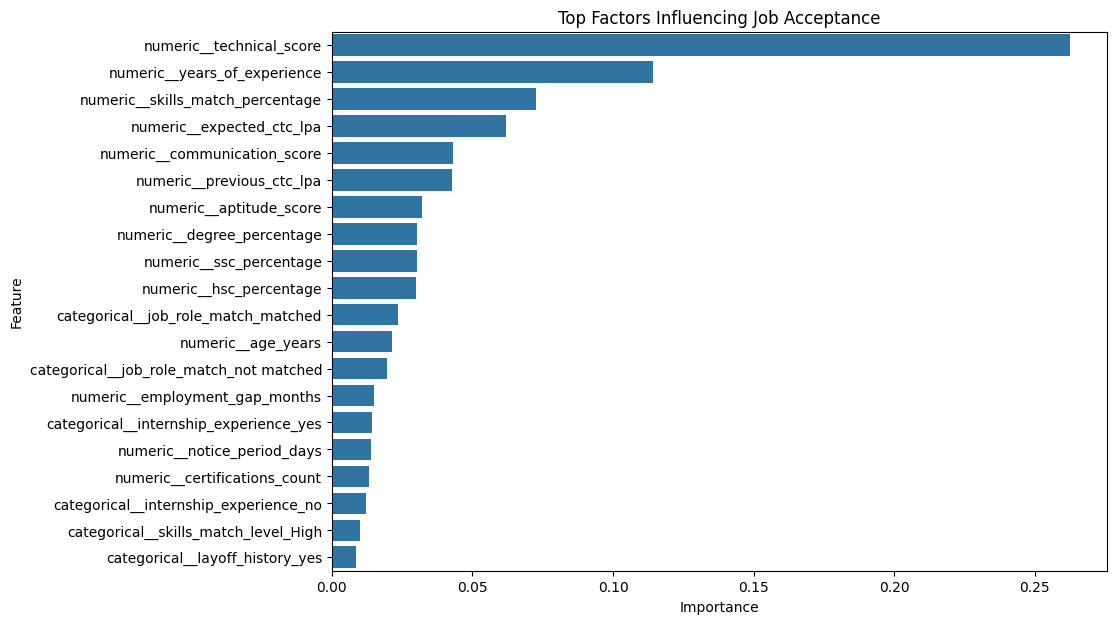

In [ ]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Top Factors Influencing Job Acceptance")
plt.show()

In [ ]:
df.to_csv(
    "cleaned_job_acceptance_dataset.csv",
    index=False
)

In [ ]:
from google.colab import files

files.download(
    "cleaned_job_acceptance_dataset.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install pymysql sqlalchemy

In [ ]:
!pip install mysql-connector-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.7/21.7 MB 56.9 MB/s eta 0:00:00


In [ ]:
import mysql.connector

conn = mysql.connector.connect(
    host="gateway01.ap-southeast-1.prod.aws.tidbcloud.com",
    port=4000,
    user="2ow7fzo5mRAMRmu.root",
    password="VORWif0dPOWA4Uuh",
    database="job_acceptance_db"
)

print("Connected to TiDB successfully!")

Connected to TiDB successfully!


In [ ]:
cursor = conn.cursor()

cursor.execute("SHOW TABLES")

for table in cursor.fetchall():
    print(table[0])

job_candidates


In [ ]:
cursor.execute("SELECT * FROM job_candidates")

for row in cursor.fetchall():
    print(row)

In [ ]:
pip install streamlit pymysql

In [ ]:
%%writefile /content/app.py
import streamlit as st
import pymysql
import pandas as pd
import plotly.express as px

# Database connection
@st.cache_resource
def get_connection():
connection = pymysql.connect(
    host="gateway01.ap-southeast-1.prod.aws.tidbcloud.com",
    port=4000,
    user="2ow7fzo5mRAMRmu.root",
    password="VORWif0dPOWA4Uuh",
    database="job_acceptance_db",
    ssl={"ssl": {}}
)
 return connection
# ---------------------------------
# PAGE CONFIG
# ---------------------------------

st.set_page_config(
    page_title="Job Acceptance Prediction",
    page_icon="🎯",
    layout="wide"
)


# ---------------------------------
# TITLE
# ---------------------------------

st.title("🎯 Job Acceptance Prediction System")

st.markdown(
    """
    ### HR Analytics & Machine Learning Dashboard

    Analyze candidate placement and job acceptance patterns
    using data analytics and machine learning.
    """
)

# =========================================================
# DATABASE CONNECTION
# =========================================================

connection = pymysql.connect(

        host="gateway01.ap-southeast-1.prod.aws.tidbcloud.com",
        port=4000,
        user="2ow7fzo5mRAMRmu.root",
        password="VORWif0dPOWA4Uuh",
        database="job_acceptance_db",
        ssl={}
    )

    # =========================================================
# TEST TiDB CONNECTION
# =========================================================

try:

    engine = get_connection()

    with engine.connect() as connection:

        connection.execute(
            text("SELECT 1")
        )

    st.sidebar.success(
        "✅ TiDB Connected"
    )

except Exception as e:

    st.sidebar.error(
        "❌ TiDB Connection Failed"
    )

    st.error(
        f"Database connection error: {e}"
    )

    st.stop()


# =========================================================
# LOAD DATA FROM TiDB
# =========================================================

@st.cache_data(ttl=300)
def load_data():

    query = """
        SELECT *
        FROM job_candidates
    """

    data = pd.read_sql(
        query,
        engine
    )

    return data


try:

    df = load_data()

except Exception as e:

    st.error(
        f"Unable to load job_candidates table: {e}"
    )

    st.stop()


# =========================================================
# CHECK DATA
# =========================================================

if df.empty:

    st.warning(
        "The job_candidates table is empty."
    )

    st.stop()


# =========================================================
# SIDEBAR
# =========================================================

st.sidebar.header("🔍 Filters")


# ---------------------------------------------------------
# Company Tier Filter
# ---------------------------------------------------------

if "company_tier" in df.columns:

    company_options = sorted(
        df["company_tier"]
        .dropna()
        .unique()
        .tolist()
    )

    selected_company = st.sidebar.multiselect(
        "Company Tier",
        company_options,
        default=company_options
    )

    df = df[
        df["company_tier"].isin(
            selected_company
        )
    ]


# ---------------------------------------------------------
# Experience Filter
# ---------------------------------------------------------

if "experience_category" in df.columns:

    experience_options = sorted(
        df["experience_category"]
        .dropna()
        .unique()
        .tolist()
    )

    selected_experience = st.sidebar.multiselect(
        "Experience Category",
        experience_options,
        default=experience_options
    )

    df = df[
        df["experience_category"].isin(
            selected_experience
        )
    ]


# ---------------------------------------------------------
# Target Filter
# ---------------------------------------------------------

if "target" in df.columns:

    selected_status = st.sidebar.multiselect(
        "Job Status",
        ["Accepted", "Rejected"],
        default=["Accepted", "Rejected"]
    )

    if selected_status:

        target_values = []

        if "Accepted" in selected_status:
            target_values.append(1)

        if "Rejected" in selected_status:
            target_values.append(0)

        df = df[
            df["target"].isin(
                target_values
            )
        ]


# =========================================================
# KPI CALCULATIONS
# =========================================================

total_candidates = len(df)


# ---------------------------------------------------------
# Acceptance Rate
# ---------------------------------------------------------

if "target" in df.columns and len(df) > 0:

    acceptance_rate = (
        df["target"].mean() * 100
    )

else:

    acceptance_rate = 0


# ---------------------------------------------------------
# Interview Score
# ---------------------------------------------------------

if "interview_score" in df.columns:

    avg_interview_score = (
        df["interview_score"].mean()
    )

else:

    avg_interview_score = 0


# ---------------------------------------------------------
# Skills Match
# ---------------------------------------------------------

if "skills_match_percentage" in df.columns:

    avg_skills_match = (
        df["skills_match_percentage"].mean()
    )

else:

    avg_skills_match = 0


# =========================================================
# KPI DISPLAY
# =========================================================

st.subheader("📊 Key Performance Indicators")

col1, col2, col3, col4 = st.columns(4)


col1.metric(
    "👥 Total Candidates",
    f"{total_candidates:,}"
)


col2.metric(
    "✅ Job Acceptance Rate",
    f"{acceptance_rate:.2f}%"
)


col3.metric(
    "🎤 Avg Interview Score",
    f"{avg_interview_score:.2f}"
)


col4.metric(
    "🛠️ Avg Skills Match",
    f"{avg_skills_match:.2f}%"
)


st.divider()


# =========================================================
# JOB ACCEPTANCE DISTRIBUTION
# =========================================================

if "target" in df.columns:

    st.subheader(
        "📌 Job Acceptance Distribution"
    )

    target_counts = (
        df["target"]
        .value_counts()
        .reset_index()
    )

    target_counts.columns = [
        "Status",
        "Count"
    ]

    target_counts["Status"] = (
        target_counts["Status"]
        .map({
            1: "Accepted",
            0: "Rejected"
        })
        .fillna(
            target_counts["Status"].astype(str)
        )
    )

    fig = px.pie(
        target_counts,
        names="Status",
        values="Count",
        hole=0.4,
        title="Job Acceptance Distribution"
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )


# =========================================================
# COMPANY TIER ANALYSIS
# =========================================================

if (
    "company_tier" in df.columns
    and "target" in df.columns
):

    st.subheader(
        "🏢 Acceptance Rate by Company Tier"
    )

    company_df = (
        df.groupby("company_tier")["target"]
        .mean()
        .mul(100)
        .reset_index()
    )

    company_df.columns = [
        "Company Tier",
        "Acceptance Rate"
    ]

    fig = px.bar(
        company_df,
        x="Company Tier",
        y="Acceptance Rate",
        text_auto=".2f",
        title="Acceptance Rate by Company Tier"
    )

    fig.update_layout(
        yaxis_title="Acceptance Rate (%)",
        xaxis_title="Company Tier"
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )


# =========================================================
# INTERVIEW SCORE ANALYSIS
# =========================================================

if (
    "interview_score" in df.columns
    and "target" in df.columns
):

    st.subheader(
        "🎤 Interview Score vs Job Acceptance"
    )

    interview_df = df.copy()

    interview_df["Status"] = (
        interview_df["target"]
        .map({
            1: "Accepted",
            0: "Rejected"
        })
    )

    fig = px.box(
        interview_df,
        x="Status",
        y="interview_score",
        title="Interview Score vs Job Acceptance",
        labels={
            "interview_score": "Interview Score",
            "Status": "Job Status"
        }
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )


# =========================================================
# EXPERIENCE ANALYSIS
# =========================================================

if (
    "experience_category" in df.columns
    and "target" in df.columns
):

    st.subheader(
        "💼 Experience vs Job Acceptance"
    )

    experience_df = (
        df.groupby(
            "experience_category"
        )["target"]
        .mean()
        .mul(100)
        .reset_index()
    )

    experience_df.columns = [
        "Experience",
        "Acceptance Rate"
    ]

    fig = px.bar(
        experience_df,
        x="Experience",
        y="Acceptance Rate",
        text_auto=".2f",
        title="Experience Category vs Acceptance Rate"
    )

    fig.update_layout(
        yaxis_title="Acceptance Rate (%)",
        xaxis_title="Experience Category"
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )


# =========================================================
# SKILLS MATCH ANALYSIS
# =========================================================

if (
    "skills_match_percentage" in df.columns
    and "target" in df.columns
):

    st.subheader(
        "🛠️ Skills Match vs Job Acceptance"
    )

    skills_df = df.copy()

    skills_df["Status"] = (
        skills_df["target"]
        .map({
            1: "Accepted",
            0: "Rejected"
        })
    )

    fig = px.box(
        skills_df,
        x="Status",
        y="skills_match_percentage",
        title="Skills Match Percentage vs Job Acceptance",
        labels={
            "skills_match_percentage":
                "Skills Match (%)",
            "Status":
                "Job Status"
        }
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )


# =========================================================
# CERTIFICATION ANALYSIS
# =========================================================

if (
    "certification_count" in df.columns
    and "target" in df.columns
):

    st.subheader(
        "🎓 Certification Count vs Acceptance"
    )

    certification_df = (
        df.groupby(
            "certification_count"
        )["target"]
        .mean()
        .mul(100)
        .reset_index()
    )

    certification_df.columns = [
        "Certification Count",
        "Acceptance Rate"
    ]

    fig = px.bar(
        certification_df,
        x="Certification Count",
        y="Acceptance Rate",
        text_auto=".2f",
        title="Certification Count vs Job Acceptance"
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )


# =========================================================
# HIGH RISK CANDIDATES
# =========================================================

if (
    "interview_score" in df.columns
    and "skills_match_percentage" in df.columns
):

    high_risk = df[
        (df["interview_score"] < 50)
        &
        (df["skills_match_percentage"] < 50)
    ]

    high_risk_percentage = (
        len(high_risk)
        / len(df)
        * 100
        if len(df) > 0
        else 0
    )

    st.subheader(
        "⚠️ High-Risk Candidate Analysis"
    )

    risk_col1, risk_col2 = st.columns(2)

    risk_col1.metric(
        "High-Risk Candidates",
        f"{len(high_risk):,}"
    )

    risk_col2.metric(
        "High-Risk Percentage",
        f"{high_risk_percentage:.2f}%"
    )


# =========================================================
# CANDIDATE DATA
# =========================================================

st.divider()

st.subheader(
    "📋 Candidate Data"
)

st.dataframe(
    df,
    use_container_width=True,
    height=500
)


# =========================================================
# FOOTER
# =========================================================

st.divider()

st.caption(
    "🎯 Job Acceptance Prediction System | "
    "HR Analytics | Python + TiDB + Streamlit"
)

Writing /content/app.py


In [ ]:
!wget -q -O - ipv4.icanhazip.com

34.185.67.200


In [ ]:
!streamlit run app.py & npx localtunnel --port 8501

⠙

⠹⠸⠼⠴⠦your url is: https://funny-suns-dream.loca.lt
2026-09-27 09:45:48.989 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.185.67.200:8501

2026-09-27 09:46:40.186 Script compilation error
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/streamlit/runtime/scriptrunner/script_runner.py", line 729, in _run_script
    code = self._script_cache.get_bytecode(script_path)
  File "/usr/local/lib/python3.13/dist-packages/streamlit/runtime/scriptrunner/script_cache.py", line 72, in get_bytecode
    filebody = magic.add_magic(filebody, script_path)
  File "/usr/local/lib/python3.13/dist-packages/streamlit/runtime/scriptrunner/magic.py", line 45, in add_magic
    tree = ast.parse(code, script_path, "exec")
  File "/usr/lib/python3.13/ast.py", line 50, in parse
    return compile(source, filename, mode, flags,
          

In [ ]:
!pip install --upgrade streamlit

In [ ]:
!pip install streamlit pymysql pyngrok

In [ ]:
!streamlit run app.py &>/content/logs.txt &

In [ ]:
!pip install streamlit pymysql pyngrok -q

In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("3HiWvBFhqGV7lOSLWzJKhe7N8rj_6G11MBqzcoHL6KEz4KTM8")

print("ngrok authentication successful")

ngrok authentication successful


In [ ]:
from pyngrok import ngrok

ngrok.kill()

public_url = ngrok.connect(8501)

print("Streamlit URL:", public_url)

Streamlit URL: NgrokTunnel: "https://chirping-verbalize-cymbal.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
!pkill -f streamlit

In [ ]:
!streamlit run /content/app.py > /content/streamlit.log 2>&1 &